In [5]:
!pip install gluonts
from pathlib import Path
import numpy as np
import pandas as pd
from gluonts.dataset.repository import get_dataset
from gluonts.dataset.common import ListDataset
import numpy as np

USE_ARCHIVED_AGGREGATES = False
electricity = get_dataset("electricity")
traffic = get_dataset("traffic")

electricity_train = list(electricity.train)
electricity_test = list(electricity.test)

traffic_train = list(traffic.train)
traffic_test = list(traffic.test)

def combine_gluonts_train_test(train_entries, test_entries, freq):
    """
    Retain the longest available target for each item_id.

    GluonTS test entries already include the training history, so the
    targets should not be concatenated.
    """
    longest_entry = {}

    for entry in train_entries + test_entries:
        item_id = str(entry["item_id"])

        if (
            item_id not in longest_entry
            or len(entry["target"])
            > len(longest_entry[item_id]["target"])
        ):
            copied_entry = dict(entry)
            copied_entry["target"] = np.asarray(
                entry["target"]
            ).copy()

            longest_entry[item_id] = copied_entry

    def sort_key(item_id):
        try:
            return int(item_id)
        except ValueError:
            return item_id

    combined_entries = [
        longest_entry[item_id]
        for item_id in sorted(longest_entry, key=sort_key)
    ]

    return ListDataset(
        combined_entries,
        freq=freq,
    )


electricity_all = combine_gluonts_train_test(
    electricity_train,
    electricity_test,
    electricity.metadata.freq,
)

traffic_all = combine_gluonts_train_test(
    traffic_train,
    traffic_test,
    traffic.metadata.freq,
)

electricity_all = list(electricity_all)
traffic_all = list(traffic_all)

print("Electricity series:", len(electricity_all))
print("Traffic series:", len(traffic_all))

print(
    "Electricity longest series length:",
    len(electricity_all[0]["target"]),
)

print(
    "Traffic longest series length:",
    len(traffic_all[0]["target"]),
)

Electricity series: 321
Traffic series: 862
Electricity longest series length: 21212
Traffic longest series length: 14204


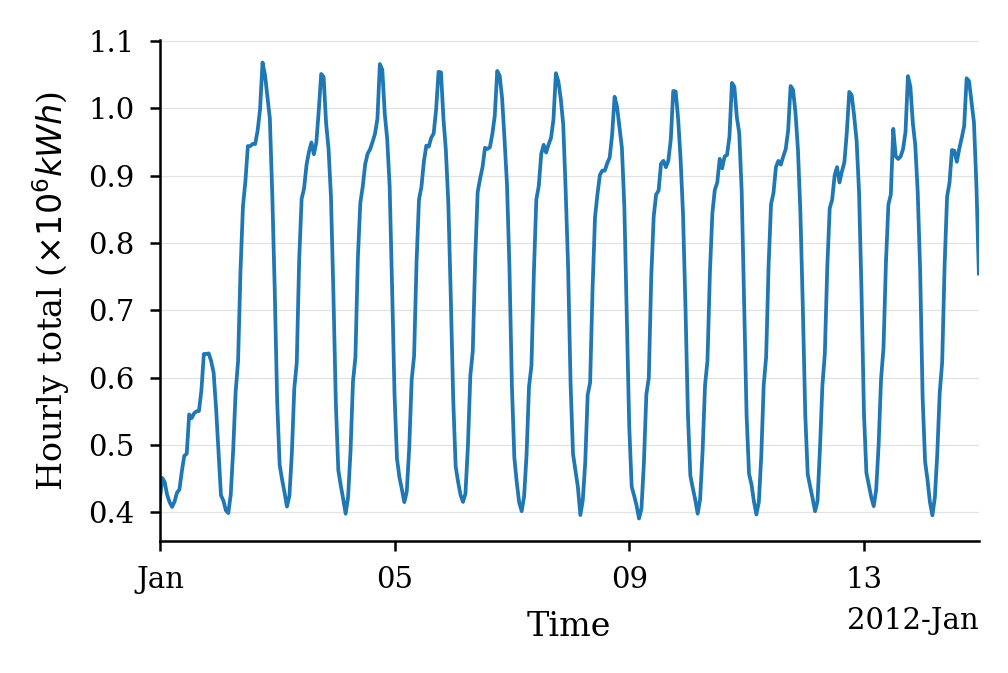

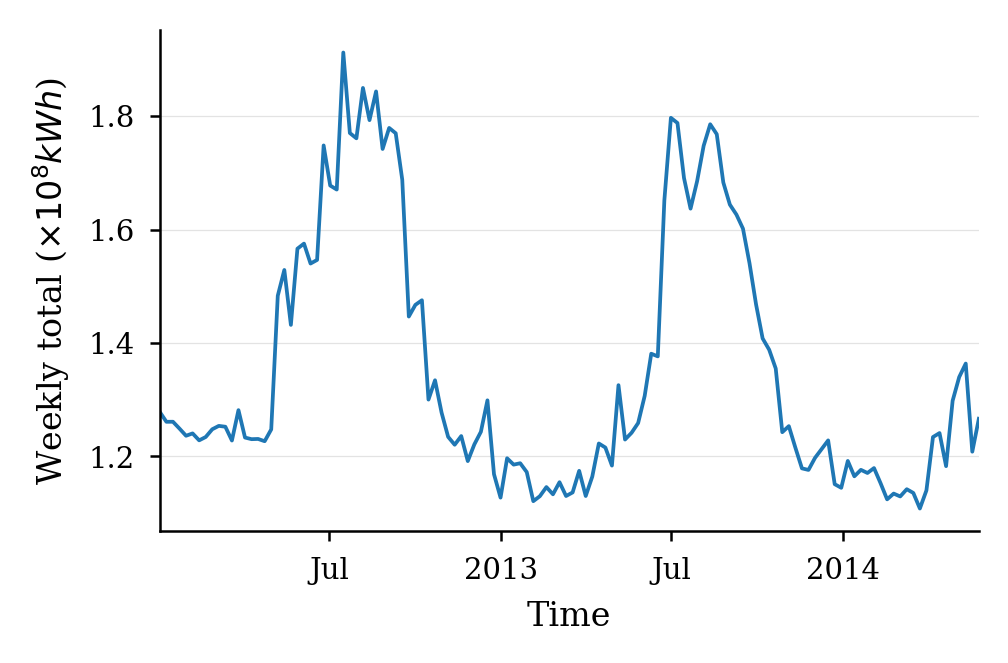

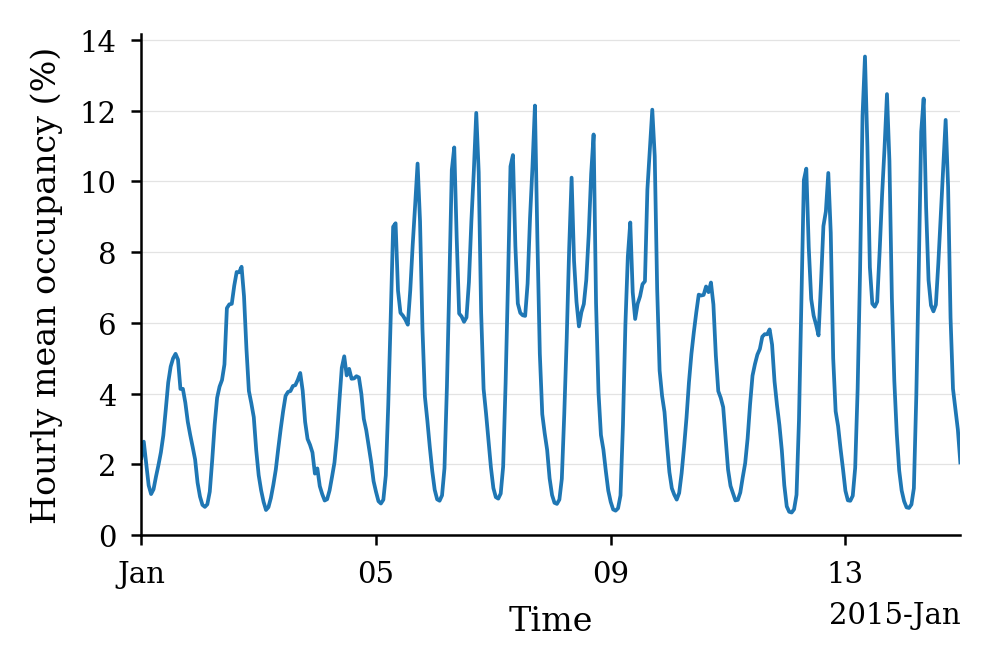

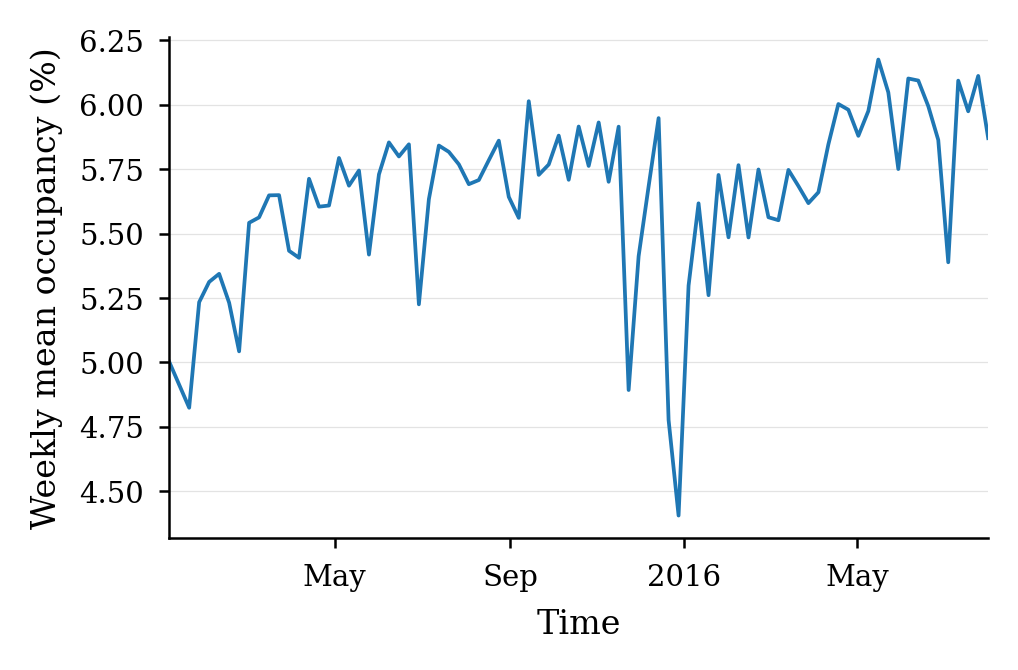

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def build_aggregate_series(entries, freq, how="sum"):
    """
    Construct one aggregate time series from multiple GluonTS entries.

    Parameters
    ----------
    entries : list
        GluonTS dataset entries.
    freq : str
        Sampling frequency of the dataset.
    how : {"sum", "mean"}
        Aggregation across individual series at each timestamp.

    Returns
    -------
    pandas.Series
        Aggregate time series with a DatetimeIndex.
    """
    common_len = min(
        len(np.asarray(entry["target"]))
        for entry in entries
    )

    data_matrix = np.vstack([
        np.asarray(entry["target"], dtype=float)[:common_len]
        for entry in entries
    ])

    if how == "sum":
        aggregate_values = np.nansum(data_matrix, axis=0)
    elif how == "mean":
        aggregate_values = np.nanmean(data_matrix, axis=0)
    else:
        raise ValueError("how must be either 'sum' or 'mean'")

    start = entries[0]["start"]

    if hasattr(start, "to_timestamp"):
        start_timestamp = start.to_timestamp()
    else:
        start_timestamp = pd.Timestamp(start)

    time_index = pd.date_range(
        start=start_timestamp,
        periods=common_len,
        freq=freq,
    )

    return pd.Series(
        aggregate_values,
        index=time_index,
    )


def format_time_axis(ax, minticks=4, maxticks=6):
    """
    Apply compact date formatting suitable for an IEEE paper.
    """
    locator = mdates.AutoDateLocator(
        minticks=minticks,
        maxticks=maxticks,
    )

    formatter = mdates.ConciseDateFormatter(locator)

    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)

    ax.tick_params(
        direction="out",
        length=2.5,
        width=0.6,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_single_series(
    series,
    ylabel,
    xlabel,
    save_name,
    figsize=(3.5, 2.2),
):
    """
    Create and save one independent one-column IEEE-style figure.
    """
    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(
        series.index,
        series.values,
        linewidth=0.9,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    ax.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    ax.margins(x=0)

    format_time_axis(ax)

    fig.subplots_adjust(
        left=0.20,
        right=0.98,
        top=0.96,
        bottom=0.20,
    )

    plt.savefig(
        f"{save_name}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{save_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ----------------------------------------------------
# IEEE-style plotting settings
# ----------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.9,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ----------------------------------------------------
# Construct hourly aggregate series
# ----------------------------------------------------

if not USE_ARCHIVED_AGGREGATES:
    # Sum electricity consumption across all clients
    electricity_series = build_aggregate_series(
        electricity_all,
        electricity.metadata.freq,
        how="sum",
    )

    # Average traffic occupancy across all sensors
    traffic_series = build_aggregate_series(
        traffic_all,
        traffic.metadata.freq,
        how="mean",
    )


# ----------------------------------------------------
# Construct weekly aggregate series
# ----------------------------------------------------

# Sum hourly aggregate electricity values within each week
electricity_weekly = electricity_series.resample(
    "W-MON",
    label="left",
    closed="left",
).sum()

# Average hourly aggregate traffic values within each week
traffic_weekly = traffic_series.resample(
    "W-MON",
    label="left",
    closed="left",
).mean()


# Remove potentially incomplete first and last weeks
electricity_weekly = electricity_weekly.iloc[1:-1]
traffic_weekly = traffic_weekly.iloc[1:-1]


# ----------------------------------------------------
# Select representative hourly windows
# ----------------------------------------------------

# Number of days shown in each hourly plot
hourly_days = 14
hourly_points = 24 * hourly_days

electricity_hourly_zoom = electricity_series.iloc[:hourly_points]
traffic_hourly_zoom = traffic_series.iloc[:hourly_points]


# ----------------------------------------------------
# Scale the values for cleaner axes
# ----------------------------------------------------

# Electricity
electricity_hourly_plot = electricity_hourly_zoom / 1e6
electricity_weekly_plot = electricity_weekly / 1e8

# Traffic occupancy as percentages
traffic_hourly_plot = traffic_hourly_zoom * 100
traffic_weekly_plot = traffic_weekly * 100


# ----------------------------------------------------
# Generate four separate plots
# ----------------------------------------------------

# 1. Hourly electricity plot
plot_single_series(
    series=electricity_hourly_plot,
    ylabel=r"Hourly total ($\times 10^6 kWh$)",
    xlabel="Time",
    save_name="electricity_hourly",
)

# 2. Weekly electricity plot
plot_single_series(
    series=electricity_weekly_plot,
    ylabel=r"Weekly total ($\times 10^8 kWh$)",
    xlabel="Time",
    save_name="electricity_weekly",
)

# 3. Hourly traffic plot
plot_single_series(
    series=traffic_hourly_plot,
    ylabel="Hourly mean occupancy (%)",
    xlabel="Time",
    save_name="traffic_hourly",
)

# 4. Weekly traffic plot
plot_single_series(
    series=traffic_weekly_plot,
    ylabel="Weekly mean occupancy (%)",
    xlabel="Time",
    save_name="traffic_weekly",
)

Detection threshold m = 27

Electricity
Total observations: 21212
Training observations: 1060
Calibration observations: 1060
Testing observations: 19092

    Dataset      Method  Coverage  Avg. Width     RMSE  Modes Learned  Detections
Electricity Standard CP  0.655458    0.087322 0.063007            NaN         NaN
Electricity         ACI  0.899696    0.168740 0.063007            NaN         NaN
Electricity        OMAC  0.986120    0.326722      NaN            3.0         2.0

OMAC method detection threshold: 27
Number of learned modes: 3
Number of detected shifts: 2
Detection times:
   2012-04-13 02:00:00
   2012-05-12 17:00:00


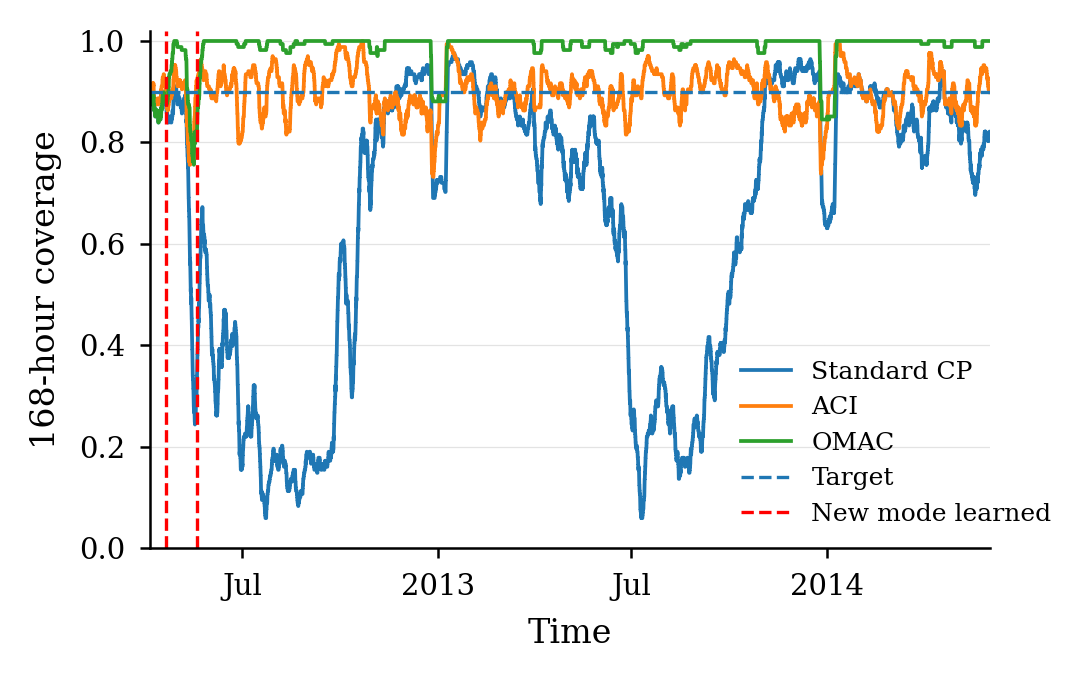


Traffic
Total observations: 14204
Training observations: 710
Calibration observations: 710
Testing observations: 12784

Dataset      Method  Coverage  Avg. Width     RMSE  Modes Learned  Detections
Traffic Standard CP  0.917397    1.951968 0.588319            NaN         NaN
Traffic         ACI  0.900579    1.802194 0.588319            NaN         NaN
Traffic        OMAC  0.926627    2.162349      NaN            2.0         1.0

OMAC method detection threshold: 27
Number of learned modes: 2
Number of detected shifts: 1
Detection times:
   2015-11-23 15:00:00


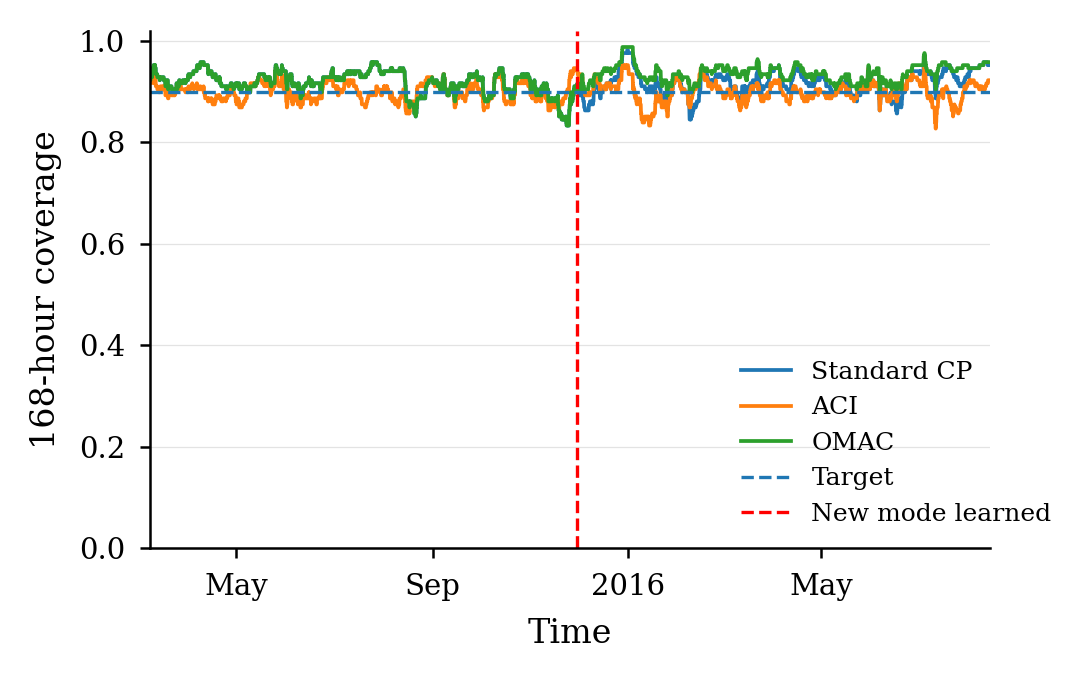


Combined real-world results


,Dataset,Method,Coverage,Avg. Width,RMSE,Modes Learned,Detections
0,Electricity,Standard CP,0.655458,0.087322,0.063007,NaN,NaN
1,Electricity,ACI,0.899696,0.168740,0.063007,NaN,NaN
2,Electricity,OMAC,0.986120,0.326722,NaN,3.0,2.0
3,Traffic,Standard CP,0.917397,1.951968,0.588319,NaN,NaN
4,Traffic,ACI,0.900579,1.802194,0.588319,NaN,NaN
5,Traffic,OMAC,0.926627,2.162349,NaN,2.0,1.0


In [7]:
# ============================================================
# Real-world conformal prediction experiments
# Standard CP vs. ACI vs. proposed online mode-learning CP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque
from dataclasses import dataclass

from sklearn.linear_model import Ridge
from scipy.stats import binom


# ------------------------------------------------------------
# Experimental hyperparameters
# ------------------------------------------------------------

ALPHA = 0.10

AR_ORDER = 24
RIDGE_LAMBDA = 1.0

# Gibbs and Candes ACI learning rate
ACI_GAMMA = 0.005

# OMAC method
W = 168
N_BUILD = 168
DELTA = 0.01

# Rolling coverage window
ROLLING_WINDOW = 168

# Initial data split
TRAIN_FRAC = 0.05
CAL_FRAC = 0.05


# Current algorithm uses the same length for detection
# and new-mode construction.
assert W == N_BUILD


# ------------------------------------------------------------
# Binomial detection threshold
# ------------------------------------------------------------

def compute_detection_threshold(W, alpha, delta):
    """
    Compute

        m = min{j : P(B >= j) <= delta},
        B ~ Binomial(W, alpha).
    """
    for j in range(W + 1):
        tail_prob = binom.sf(j - 1, W, alpha)

        if tail_prob <= delta:
            return j

    return W


DETECTION_THRESHOLD = compute_detection_threshold(
    W=W,
    alpha=ALPHA,
    delta=DELTA,
)

print("Detection threshold m =", DETECTION_THRESHOLD)


# ------------------------------------------------------------
# AR(24) ridge-regression predictor
# ------------------------------------------------------------

def fit_ar_ridge(
    y_train,
    lag=AR_ORDER,
    ridge_lambda=RIDGE_LAMBDA,
):
    """
    Fit a standardized linear AR(lag) model using ridge regression.

    The common mean and standard deviation are computed from the
    raw training time series, consistent with the Experimental
    Setup section.
    """
    y_train = np.asarray(y_train, dtype=float)

    if len(y_train) <= lag:
        raise ValueError(
            "Training series must contain more observations "
            "than the AR order."
        )

    mean_y = np.mean(y_train)
    std_y = np.std(y_train)

    if std_y < 1e-12:
        std_y = 1.0

    X = []
    target = []

    for t in range(lag, len(y_train)):

        # [Y_{t-1}, Y_{t-2}, ..., Y_{t-lag}]
        x_t = np.array(
            [
                y_train[t - j]
                for j in range(1, lag + 1)
            ],
            dtype=float,
        )

        x_t = (x_t - mean_y) / std_y

        X.append(x_t)
        target.append(y_train[t])

    X = np.asarray(X)
    target = np.asarray(target)

    model = Ridge(
        alpha=ridge_lambda,
        fit_intercept=True,
    )

    model.fit(X, target)

    return {
        "model": model,
        "mean": mean_y,
        "std": std_y,
        "lag": lag,
    }


def predict_ar(ar_model, history, t):
    """
    One-step-ahead prediction of Y_t using observations
    Y_{t-1}, ..., Y_{t-24}.
    """
    history = np.asarray(history, dtype=float)

    lag = ar_model["lag"]

    x_t = np.array(
        [
            history[t - j]
            for j in range(1, lag + 1)
        ],
        dtype=float,
    )

    x_t = (
        x_t - ar_model["mean"]
    ) / ar_model["std"]

    prediction = ar_model["model"].predict(
        x_t.reshape(1, -1)
    )[0]

    return float(prediction)


# ------------------------------------------------------------
# Conformal quantile
# ------------------------------------------------------------

def conformal_quantile(scores, alpha):
    """
    Finite-sample corrected conformal quantile.

    k = ceil((n + 1)(1 - alpha)).
    """
    scores = np.asarray(scores, dtype=float)

    n = len(scores)

    if n == 0:
        raise ValueError(
            "Calibration score set cannot be empty."
        )

    alpha = float(np.clip(alpha, 0.0, 1.0))

    k = int(
        np.ceil(
            (n + 1) * (1.0 - alpha)
        )
    )

    # Practical finite-calibration clipping
    k = min(max(k, 1), n)

    return float(
        np.partition(scores, k - 1)[k - 1]
    )


# ------------------------------------------------------------
# Calibration residuals
# ------------------------------------------------------------

def get_calibration_scores(
    ar_model,
    y,
    start,
    end,
):
    """
    Compute absolute one-step-ahead residuals over
    [start, end).
    """
    scores = []

    for t in range(start, end):

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        score = abs(
            y[t] - pred
        )

        scores.append(score)

    return np.asarray(scores)


# ------------------------------------------------------------
# Standard conformal prediction
# ------------------------------------------------------------

def run_standard_cp(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
):
    """
    Fixed AR predictor + fixed split-conformal quantile.
    """
    y = np.asarray(y, dtype=float)

    cal_start = n_train
    test_start = n_train + n_cal

    ar_model = fit_ar_ridge(
        y[:n_train],
    )

    cal_scores = get_calibration_scores(
        ar_model,
        y,
        cal_start,
        test_start,
    )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []

    for t in range(test_start, len(y)):

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q
        hi = pred + q

        predictions.append(pred)
        lower.append(lo)
        upper.append(hi)

        covered.append(
            lo <= y[t] <= hi
        )

        widths.append(
            hi - lo
        )

    return {
        "prediction": np.asarray(predictions),
        "lower": np.asarray(lower),
        "upper": np.asarray(upper),
        "covered": np.asarray(covered, dtype=bool),
        "width": np.asarray(widths),
        "q": q,
        "model": ar_model,
        "calibration_scores": cal_scores,
        "test_start": test_start,
    }


# ------------------------------------------------------------
# Adaptive Conformal Inference
# ------------------------------------------------------------

def run_aci(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
    gamma=ACI_GAMMA,
):
    """
    ACI with:

        alpha_{t+1}
        =
        alpha_t
        +
        gamma * (alpha - err_t)

    The AR(24) point predictor remains fixed.

    The conformal residual buffer is updated online while
    retaining the same size as the initial calibration set.
    """
    y = np.asarray(y, dtype=float)

    cal_start = n_train
    test_start = n_train + n_cal

    ar_model = fit_ar_ridge(
        y[:n_train],
    )

    initial_scores = get_calibration_scores(
        ar_model,
        y,
        cal_start,
        test_start,
    )

    score_buffer = deque(
        initial_scores.tolist(),
        maxlen=n_cal,
    )

    alpha_t = alpha

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []
    alpha_history = []
    q_history = []

    for t in range(test_start, len(y)):

        scores_now = np.asarray(
            score_buffer,
            dtype=float,
        )

        # Avoid requesting a quantile beyond the finite
        # calibration resolution.
        min_alpha = 1.0 / (
            len(scores_now) + 1
        )

        alpha_for_quantile = np.clip(
            alpha_t,
            min_alpha,
            1.0,
        )

        q_t = conformal_quantile(
            scores_now,
            alpha_for_quantile,
        )

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q_t
        hi = pred + q_t

        miss = int(
            not (lo <= y[t] <= hi)
        )

        predictions.append(pred)
        lower.append(lo)
        upper.append(hi)

        covered.append(
            miss == 0
        )

        widths.append(
            hi - lo
        )

        alpha_history.append(
            alpha_t
        )

        q_history.append(
            q_t
        )

        # ACI update
        alpha_t = (
            alpha_t
            +
            gamma * (
                alpha - miss
            )
        )

        # Add the newly observed residual only after
        # producing the prediction interval.
        new_score = abs(
            y[t] - pred
        )

        score_buffer.append(
            new_score
        )

    return {
        "prediction": np.asarray(predictions),
        "lower": np.asarray(lower),
        "upper": np.asarray(upper),
        "covered": np.asarray(covered, dtype=bool),
        "width": np.asarray(widths),
        "alpha_history": np.asarray(alpha_history),
        "q_history": np.asarray(q_history),
        "model": ar_model,
        "test_start": test_start,
    }


# ------------------------------------------------------------
# OMAC mode-specific model
# ------------------------------------------------------------

@dataclass
class ModeModel:
    mode_id: int
    ar_model: dict
    q: float
    created_at: int

    # Retained only for post-hoc detection-window validation.
    calibration_scores: np.ndarray | None = None


def build_mode_from_buffer(
    buffer,
    mode_id,
    created_at,
    alpha=ALPHA,
):
    """
    Construct a new mode from N_BUILD consecutive observations.

    The first half is used to fit the AR(24) model and
    the second half is used for conformal calibration.
    """
    buffer = np.asarray(
        buffer,
        dtype=float,
    )

    split = len(buffer) // 2

    if split <= AR_ORDER:
        raise ValueError(
            "Mode-building training portion is too short "
            "for AR(24)."
        )

    train_segment = buffer[:split]

    ar_model = fit_ar_ridge(
        train_segment,
    )

    cal_scores = []

    for t in range(split, len(buffer)):

        pred = predict_ar(
            ar_model,
            buffer,
            t,
        )

        cal_scores.append(
            abs(buffer[t] - pred)
        )

    cal_scores = np.asarray(
        cal_scores,
        dtype=float,
    )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    return ModeModel(
        mode_id=mode_id,
        ar_model=ar_model,
        q=q,
        created_at=created_at,
        calibration_scores=cal_scores,
    )


# ------------------------------------------------------------
# Interval-union width
# ------------------------------------------------------------

def interval_union_width(intervals):
    """
    Compute the total length of a union of possibly overlapping
    one-dimensional intervals.

    This is preferable to using max(upper)-min(lower), because
    the proposed prediction set is genuinely a union.
    """
    if len(intervals) == 0:
        return 0.0

    intervals = sorted(
        intervals,
        key=lambda x: x[0],
    )

    current_lo, current_hi = intervals[0]

    total_width = 0.0

    for lo, hi in intervals[1:]:

        if lo <= current_hi:
            current_hi = max(
                current_hi,
                hi,
            )

        else:
            total_width += (
                current_hi - current_lo
            )

            current_lo = lo
            current_hi = hi

    total_width += (
        current_hi - current_lo
    )

    return total_width


# ------------------------------------------------------------
# OMAC online mode-learning conformal prediction
# ------------------------------------------------------------

def run_mode_learning_cp(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
    W=W,
    n_build=N_BUILD,
    delta=DELTA,
):
    """
    Online mode-learning conformal prediction.

    Initial mode:
        first 5% training
        next 5% calibration

    Online:
        1. Produce one interval from every learned mode.
        2. Output their union.
        3. Record whether the union misses Y_t.
        4. Detect persistent excessive miscoverage using the
           binomial threshold.
        5. After detection, collect N_BUILD observations.
        6. Construct and store a new mode.
    """
    y = np.asarray(
        y,
        dtype=float,
    )

    test_start = (
        n_train + n_cal
    )

    threshold = compute_detection_threshold(
        W,
        alpha,
        delta,
    )

    # --------------------------------------------------------
    # Initial mode uses exactly the same initial AR model
    # and calibration data as standard CP.
    # --------------------------------------------------------

    initial_ar = fit_ar_ridge(
        y[:n_train],
    )

    initial_scores = get_calibration_scores(
        initial_ar,
        y,
        n_train,
        test_start,
    )

    initial_q = conformal_quantile(
        initial_scores,
        alpha,
    )

    modes = [
        ModeModel(
            mode_id=1,
            ar_model=initial_ar,
            q=initial_q,
            created_at=test_start - 1,
            calibration_scores=np.asarray(
                initial_scores,
                dtype=float,
            ),
        )
    ]

    # Recent union-miscoverage indicators
    error_window = deque(
        maxlen=W,
    )

    collecting = False
    candidate_buffer = []

    detection_times = []
    mode_creation_times = []

    covered = []
    widths = []

    # For plotting only: smallest lower endpoint and
    # largest upper endpoint of the union.
    hull_lower = []
    hull_upper = []

    number_of_modes = []

    # Which learned intervals covered the realized Y_t.
    covering_modes_history = []

    for t in range(
        test_start,
        len(y),
    ):

        intervals = []
        covering_modes = []

        # ----------------------------------------------------
        # Construct interval from every learned mode
        # ----------------------------------------------------

        for mode in modes:

            pred = predict_ar(
                mode.ar_model,
                y,
                t,
            )

            lo = pred - mode.q
            hi = pred + mode.q

            intervals.append(
                (lo, hi)
            )

            if lo <= y[t] <= hi:
                covering_modes.append(
                    mode.mode_id
                )

        # Prediction set is the union
        is_covered = (
            len(covering_modes) > 0
        )

        miss = int(
            not is_covered
        )

        covered.append(
            is_covered
        )

        widths.append(
            interval_union_width(
                intervals
            )
        )

        hull_lower.append(
            min(lo for lo, hi in intervals)
        )

        hull_upper.append(
            max(hi for lo, hi in intervals)
        )

        number_of_modes.append(
            len(modes)
        )

        covering_modes_history.append(
            covering_modes
        )

        # ----------------------------------------------------
        # Candidate-mode collection
        # ----------------------------------------------------

        if collecting:

            candidate_buffer.append(
                y[t]
            )

            if (
                len(candidate_buffer)
                >= n_build
            ):

                new_mode = build_mode_from_buffer(
                    candidate_buffer,
                    mode_id=len(modes) + 1,
                    created_at=t,
                    alpha=alpha,
                )

                modes.append(
                    new_mode
                )

                mode_creation_times.append(
                    t
                )

                collecting = False
                candidate_buffer = []

                # Reset detector after constructing a new mode
                error_window.clear()

        # ----------------------------------------------------
        # Distribution-shift detection
        # ----------------------------------------------------

        else:

            error_window.append(
                miss
            )

            if (
                len(error_window) == W
                and
                sum(error_window) >= threshold
            ):

                detection_times.append(
                    t
                )

                collecting = True
                candidate_buffer = []

                # Freeze/reset the detection window while
                # collecting the candidate mode.
                error_window.clear()

    return {
        "covered": np.asarray(
            covered,
            dtype=bool,
        ),
        "width": np.asarray(
            widths,
            dtype=float,
        ),
        "hull_lower": np.asarray(
            hull_lower,
            dtype=float,
        ),
        "hull_upper": np.asarray(
            hull_upper,
            dtype=float,
        ),
        "num_modes": np.asarray(
            number_of_modes,
            dtype=int,
        ),
        "covering_modes": covering_modes_history,
        "modes": modes,
        "detection_times": detection_times,
        "mode_creation_times": mode_creation_times,
        "threshold": threshold,
        "test_start": test_start,
    }


# ------------------------------------------------------------
# Summary metrics
# ------------------------------------------------------------

def summarize_results(
    dataset_name,
    y,
    standard,
    aci,
    proposed,
):
    """
    Summarize metrics that are objectively comparable on the
    real-world datasets.
    """
    test_start = standard["test_start"]

    y_test = np.asarray(
        y[test_start:],
        dtype=float,
    )

    standard_rmse = np.sqrt(
        np.mean(
            (
                standard["prediction"]
                - y_test
            ) ** 2
        )
    )

    aci_rmse = np.sqrt(
        np.mean(
            (
                aci["prediction"]
                - y_test
            ) ** 2
        )
    )

    rows = [
        {
            "Dataset": dataset_name,
            "Method": "Standard CP",
            "Coverage": np.mean(
                standard["covered"]
            ),
            "Avg. Width": np.mean(
                standard["width"]
            ),
            "RMSE": standard_rmse,
            "Modes Learned": np.nan,
            "Detections": np.nan,
        },
        {
            "Dataset": dataset_name,
            "Method": "ACI",
            "Coverage": np.mean(
                aci["covered"]
            ),
            "Avg. Width": np.mean(
                aci["width"]
            ),
            "RMSE": aci_rmse,
            "Modes Learned": np.nan,
            "Detections": np.nan,
        },
        {
            "Dataset": dataset_name,
            "Method": "OMAC",
            "Coverage": np.mean(
                proposed["covered"]
            ),
            "Avg. Width": np.mean(
                proposed["width"]
            ),

            # No single point prediction is defined by the
            # union-based proposed algorithm.
            "RMSE": np.nan,

            "Modes Learned": len(
                proposed["modes"]
            ),

            "Detections": len(
                proposed["detection_times"]
            ),
        },
    ]

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 168-hour rolling coverage
# ------------------------------------------------------------

def plot_rolling_coverage(
    time_index,
    standard,
    aci,
    proposed,
    dataset_name,
    save_name,
):
    """
    Plot rolling empirical coverage for the three methods.
    """
    rolling_standard = pd.Series(
        standard["covered"].astype(float),
        index=time_index,
    ).rolling(
        ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW,
    ).mean()

    rolling_aci = pd.Series(
        aci["covered"].astype(float),
        index=time_index,
    ).rolling(
        ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW,
    ).mean()

    rolling_proposed = pd.Series(
        proposed["covered"].astype(float),
        index=time_index,
    ).rolling(
        ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW,
    ).mean()

    fig, ax = plt.subplots(
        figsize=(3.5, 2.3)
    )

    ax.plot(
        rolling_standard.index,
        rolling_standard.values,
        label="Standard CP",
        linewidth=0.9,
    )

    ax.plot(
        rolling_aci.index,
        rolling_aci.values,
        label="ACI",
        linewidth=0.9,
    )

    ax.plot(
        rolling_proposed.index,
        rolling_proposed.values,
        label="OMAC",
        linewidth=0.9,
    )

    ax.axhline(
        1.0 - ALPHA,
        linestyle="--",
        linewidth=0.8,
        label="Target",
    )

    # --------------------------------------------------------
    # Mark when a new mode is learned
    # --------------------------------------------------------

    test_start = proposed["test_start"]

    for i, creation_t in enumerate(
        proposed["mode_creation_times"]
    ):
        local_idx = creation_t - test_start

        if 0 <= local_idx < len(time_index):
            creation_time = time_index[local_idx]

            ax.axvline(
                creation_time,
                linestyle="--",
                color="red",
                linewidth=0.8,
                label=(
                    "New mode learned"
                    if i == 0
                    else None
                ),
            )

    ax.set_ylabel(
        "168-hour coverage"
    )

    ax.set_xlabel(
        "Time"
    )

    ax.set_ylim(
        0.0,
        1.02,
    )

    ax.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    ax.legend(
      fontsize=6,
      frameon=False,
      ncol=1,
      loc="lower right",
      bbox_to_anchor=(1.1, 0.0),
  )

    ax.margins(x=0)

    format_time_axis(ax)

    fig.subplots_adjust(
        left=0.18,
        right=0.98,
        top=0.96,
        bottom=0.21,
    )

    plt.savefig(
        f"{save_name}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{save_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# Run one complete dataset experiment
# ------------------------------------------------------------

def run_real_dataset_experiment(
    series,
    dataset_name,
    save_prefix,
):
    y = np.asarray(
        series.values,
        dtype=float,
    )

    N = len(y)

    n_train = int(
        np.floor(
            TRAIN_FRAC * N
        )
    )

    n_cal = int(
        np.floor(
            CAL_FRAC * N
        )
    )

    test_start = (
        n_train + n_cal
    )

    if n_train <= AR_ORDER:
        raise ValueError(
            "Training set is too short."
        )

    print()
    print("=" * 60)
    print(dataset_name)
    print("=" * 60)

    print("Total observations:", N)
    print("Training observations:", n_train)
    print("Calibration observations:", n_cal)
    print(
        "Testing observations:",
        N - test_start,
    )

    # Standard CP
    standard = run_standard_cp(
        y,
        n_train,
        n_cal,
    )

    # ACI
    aci = run_aci(
        y,
        n_train,
        n_cal,
    )

    # OMAC method
    proposed = run_mode_learning_cp(
        y,
        n_train,
        n_cal,
    )

    summary = summarize_results(
        dataset_name,
        y,
        standard,
        aci,
        proposed,
    )

    print()
    print(summary.to_string(index=False))

    print()
    print(
        "OMAC method detection threshold:",
        proposed["threshold"],
    )

    print(
        "Number of learned modes:",
        len(proposed["modes"]),
    )

    print(
        "Number of detected shifts:",
        len(
            proposed["detection_times"]
        ),
    )

    if len(
        proposed["detection_times"]
    ) > 0:

        detection_dates = [
            series.index[t]
            for t in
            proposed["detection_times"]
        ]

        print(
            "Detection times:"
        )

        for date in detection_dates:
            print("  ", date)

    # Rolling-coverage plot
    test_index = series.index[
        test_start:
    ]

    plot_rolling_coverage(
        time_index=test_index,
        standard=standard,
        aci=aci,
        proposed=proposed,
        dataset_name=dataset_name,
        save_name=(
            f"{save_prefix}_rolling_coverage"
        ),
    )

    return {
        "standard": standard,
        "aci": aci,
        "proposed": proposed,
        "summary": summary,
        "n_train": n_train,
        "n_cal": n_cal,
        "test_start": test_start,
    }


# ============================================================
# Evaluate the two real-world datasets
# ============================================================

# Use interpretable scales for reported interval widths:
#
# Electricity:
#     unit = 10^6 kWh
#
# Traffic:
#     unit = percentage points

if USE_ARCHIVED_AGGREGATES:
    electricity_experiment_series = electricity_experiment_cached
    traffic_experiment_series = traffic_experiment_cached
else:
    electricity_experiment_series = (
        electricity_series / 1e6
    )

    traffic_experiment_series = (
        traffic_series * 100
    )


electricity_results = run_real_dataset_experiment(
    electricity_experiment_series,
    dataset_name="Electricity",
    save_prefix="electricity",
)


traffic_results = run_real_dataset_experiment(
    traffic_experiment_series,
    dataset_name="Traffic",
    save_prefix="traffic",
)


# ------------------------------------------------------------
# Combined result table
# ------------------------------------------------------------

real_world_results = pd.concat(
    [
        electricity_results["summary"],
        traffic_results["summary"],
    ],
    ignore_index=True,
)

print()
print("=" * 60)
print("Combined real-world results")
print("=" * 60)

display(
    real_world_results
)


real_world_results.to_csv(
    "real_world_cp_comparison.csv",
    index=False,
)

In [8]:
# ============================================================
# Post-hoc validation of OMAC detection windows
# ============================================================
#
# Purpose:
#   For each real-world OMAC detection, examine whether the SAME
#   W-observation window that triggered the m-threshold also shows
#   a change in nonconformity-score behavior relative to the
#   calibration-score distribution of the conformal modes that
#   were already in the library at the time of detection.
#
# Important interpretation:
#   This is a post-hoc diagnostic, not an independent confirmation
#   test, because the window is selected precisely because it has
#   unusually many miscoverage events. The KS statistic and p-values
#   quantify how different the detected window looks, but the p-values
#   should not be interpreted as selection-adjusted inferential guarantees.
#
# For an existing mode k with predictor f_k:
#
#   reference scores:
#       |Y_i - f_k(X_i)| on that mode's original calibration data
#
#   detection-window scores:
#       |Y_t - f_k(X_t)| on the W observations ending at detection time
#
# The same existing predictor f_k is used for both samples.
# ============================================================

from scipy.stats import ks_2samp


def holm_adjust(p_values):
    """
    Holm-adjust a collection of p-values.
    """
    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    m = len(p_values)

    if m == 0:
        return np.asarray(
            [],
            dtype=float,
        )

    order = np.argsort(
        p_values
    )

    adjusted = np.empty(
        m,
        dtype=float,
    )

    running_max = 0.0

    for rank, idx in enumerate(order):
        adjusted_value = (
            (m - rank) * p_values[idx]
        )

        running_max = max(
            running_max,
            adjusted_value,
        )

        adjusted[idx] = min(
            running_max,
            1.0,
        )

    return adjusted


def detection_window_scores_under_mode(
    y,
    mode,
    detection_t,
    W,
):
    """
    Compute absolute one-step-ahead residuals over the detection
    window using one already-learned mode's fixed AR predictor.
    """
    y = np.asarray(
        y,
        dtype=float,
    )

    start = (
        detection_t - W + 1
    )

    if start < AR_ORDER:
        raise ValueError(
            "Detection window begins before enough AR lags "
            "are available."
        )

    scores = []

    for t in range(
        start,
        detection_t + 1,
    ):
        pred = predict_ar(
            mode.ar_model,
            y,
            t,
        )

        scores.append(
            abs(y[t] - pred)
        )

    return np.asarray(
        scores,
        dtype=float,
    )


def validate_detection_windows(
    series,
    experiment_results,
    dataset_name,
    alpha_test=0.05,
    W=W,
):
    """
    Compare each OMAC detection window with the calibration-score
    distribution of every conformal mode that already existed at
    the detection time.

    Holm correction is applied across the existing-mode comparisons
    for each detection separately.
    """
    y = np.asarray(
        series.values,
        dtype=float,
    )

    omac = experiment_results[
        "proposed"
    ]

    modes = omac[
        "modes"
    ]

    detection_times = omac[
        "detection_times"
    ]

    covered = np.asarray(
        omac["covered"],
        dtype=bool,
    )

    test_start = omac[
        "test_start"
    ]

    threshold = omac[
        "threshold"
    ]

    rows = []

    for detection_number, detection_t in enumerate(
        detection_times,
        start=1,
    ):
        # Modes that were already available when this detection occurred.
        existing_modes = [
            mode
            for mode in modes
            if mode.created_at < detection_t
        ]

        raw_p_values = []
        pairwise_rows = []

        # Number of union misses in the exact W-observation window
        # that triggered the detector.
        local_end = (
            detection_t - test_start
        )

        local_start = (
            local_end - W + 1
        )

        detection_misses = int(
            np.sum(
                ~covered[
                    local_start:
                    local_end + 1
                ]
            )
        )

        detection_date = (
            series.index[
                detection_t
            ]
        )

        for mode in existing_modes:
            reference_scores = np.asarray(
                mode.calibration_scores,
                dtype=float,
            )

            if (
                mode.calibration_scores is None
                or len(reference_scores) == 0
            ):
                continue

            window_scores = (
                detection_window_scores_under_mode(
                    y=y,
                    mode=mode,
                    detection_t=detection_t,
                    W=W,
                )
            )

            ks_statistic, raw_p = (
                ks_2samp(
                    reference_scores,
                    window_scores,
                    alternative="two-sided",
                    method="auto",
                )
            )

            raw_p_values.append(
                raw_p
            )

            pairwise_rows.append({
                "Dataset": dataset_name,
                "Detection": detection_number,
                "Detection Time": detection_date,
                "Existing Mode": mode.mode_id,
                "Misses in Window": detection_misses,
                "Threshold m": threshold,
                "KS Statistic": ks_statistic,
                "Raw p-value": raw_p,
                "Calibration n": len(
                    reference_scores
                ),
                "Detection-window n": len(
                    window_scores
                ),
            })

        adjusted_p_values = holm_adjust(
            raw_p_values
        )

        for row, adjusted_p in zip(
            pairwise_rows,
            adjusted_p_values,
        ):
            row[
                "Holm p-value"
            ] = adjusted_p

            row[
                "Significant"
            ] = (
                adjusted_p
                < alpha_test
            )

            rows.append(
                row
            )

    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------
# Run the detection-window validation on the two real-world
# datasets used in the main AR(24) experiments.
# ------------------------------------------------------------

electricity_detection_tests = (
    validate_detection_windows(
        series=electricity_experiment_series,
        experiment_results=electricity_results,
        dataset_name="Electricity",
        alpha_test=0.05,
        W=W,
    )
)

traffic_detection_tests = (
    validate_detection_windows(
        series=traffic_experiment_series,
        experiment_results=traffic_results,
        dataset_name="Traffic",
        alpha_test=0.05,
        W=W,
    )
)


real_world_detection_window_tests = (
    pd.concat(
        [
            electricity_detection_tests,
            traffic_detection_tests,
        ],
        ignore_index=True,
    )
)

print()
print("=" * 80)
print("Post-hoc OMAC detection-window validation")
print("=" * 80)

display(
    real_world_detection_window_tests
)


# For each detection, summarize whether the detection window differs
# significantly from all conformal modes that existed at that time.
if len(
    real_world_detection_window_tests
) > 0:

    detection_window_summary = (
        real_world_detection_window_tests
        .groupby(
            [
                "Dataset",
                "Detection",
                "Detection Time",
                "Misses in Window",
                "Threshold m",
            ],
            as_index=False,
        )
        .agg(
            Existing_Modes_Tested=(
                "Existing Mode",
                "count",
            ),
            Significant_Comparisons=(
                "Significant",
                "sum",
            ),
            Different_From_All_Existing_Modes=(
                "Significant",
                "all",
            ),
        )
    )

    print()
    print(
        "Summary by OMAC detection"
    )

    display(
        detection_window_summary
    )


real_world_detection_window_tests.to_csv(
    "real_world_omac_detection_window_tests.csv",
    index=False,
)



Post-hoc OMAC detection-window validation


,Dataset,Detection,Detection Time,Existing Mode,Misses in Window,Threshold m,KS Statistic,Raw p-value,Calibration n,Detection-window n,Holm p-value,Significant
0,Electricity,1,2012-04-13 02:00:00,1,27,27,0.167857,4.822054e-04,1060,168,4.822054e-04,True
1,Electricity,2,2012-05-12 17:00:00,1,27,27,0.363612,1.240716e-17,1060,168,2.481432e-17,True
2,Electricity,2,2012-05-12 17:00:00,2,27,27,0.220238,8.142161e-03,84,168,8.142161e-03,True
3,Traffic,1,2015-11-23 15:00:00,1,27,27,0.159390,1.738165e-03,710,168,1.738165e-03,True



Summary by OMAC detection


,Dataset,Detection,Detection Time,Misses in Window,Threshold m,Existing_Modes_Tested,Significant_Comparisons,Different_From_All_Existing_Modes
0,Electricity,1,2012-04-13 02:00:00,27,27,1,1,True
1,Electricity,2,2012-05-12 17:00:00,27,27,2,2,True
2,Traffic,1,2015-11-23 15:00:00,27,27,1,1,True



Electricity: AR(4) short-warm-up experiment
Total observations: 21212
AR order: 4
Training observations: 12 (12 hours)
Calibration observations: 12 (12 hours)
Total initial warm-up: 24 (24 hours)
Testing observations: 21188
Detection window: 12 hours
Mode-building window: 24 hours

    Dataset             Setting      Method  Coverage  Avg. Width     RMSE  Modes Learned  Detections
Electricity AR(4), 24-h warm-up Standard CP  0.279875    0.249831 0.283674            NaN         NaN
Electricity AR(4), 24-h warm-up         ACI  0.789362    0.762161 0.283674            NaN         NaN
Electricity AR(4), 24-h warm-up        OMAC  0.991269    1.081336      NaN            4.0         3.0

Detection threshold: 5
Number of learned modes: 4
Number of detected shifts: 3
Detection times:
   2012-01-02 13:00:00
   2012-03-25 04:00:00
   2012-07-21 16:00:00
Mode creation times:
   2012-01-03 13:00:00
   2012-03-26 04:00:00
   2012-07-22 16:00:00


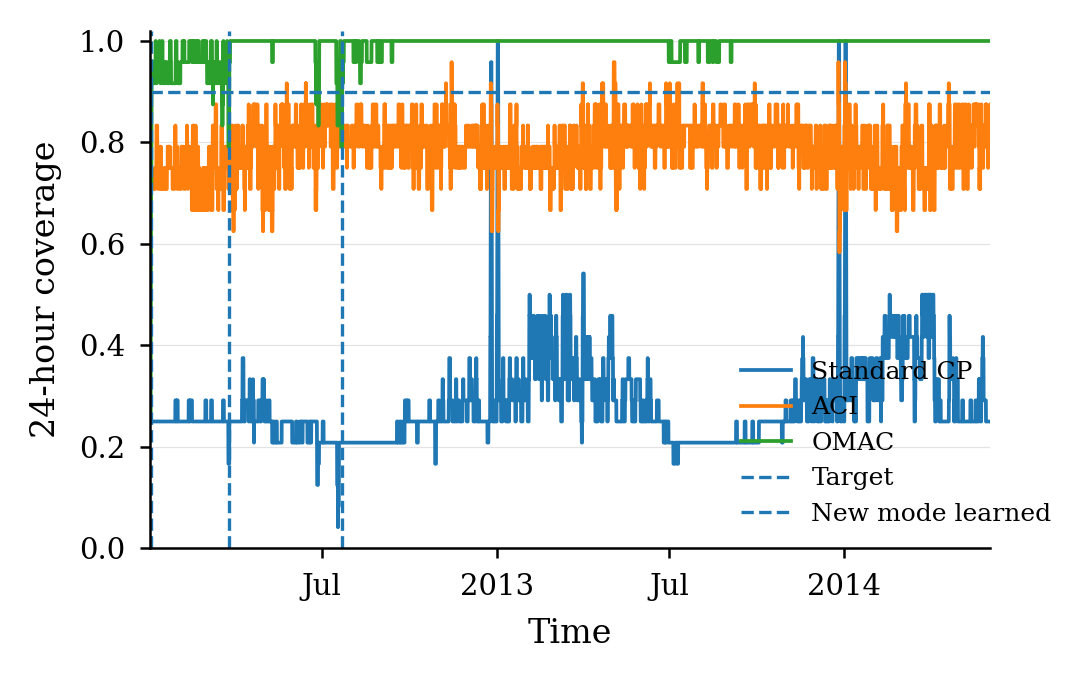


Traffic: AR(4) short-warm-up experiment
Total observations: 14204
AR order: 4
Training observations: 12 (12 hours)
Calibration observations: 12 (12 hours)
Total initial warm-up: 24 (24 hours)
Testing observations: 14180
Detection window: 12 hours
Mode-building window: 24 hours

Dataset             Setting      Method  Coverage  Avg. Width     RMSE  Modes Learned  Detections
Traffic AR(4), 24-h warm-up Standard CP  0.746262    2.503605 1.474558            NaN         NaN
Traffic AR(4), 24-h warm-up         ACI  0.897884    6.011447 1.474558            NaN         NaN
Traffic AR(4), 24-h warm-up        OMAC  0.998166   16.488956      NaN            2.0         1.0

Detection threshold: 5
Number of learned modes: 2
Number of detected shifts: 1
Detection times:
   2015-01-06 10:00:00
Mode creation times:
   2015-01-07 10:00:00


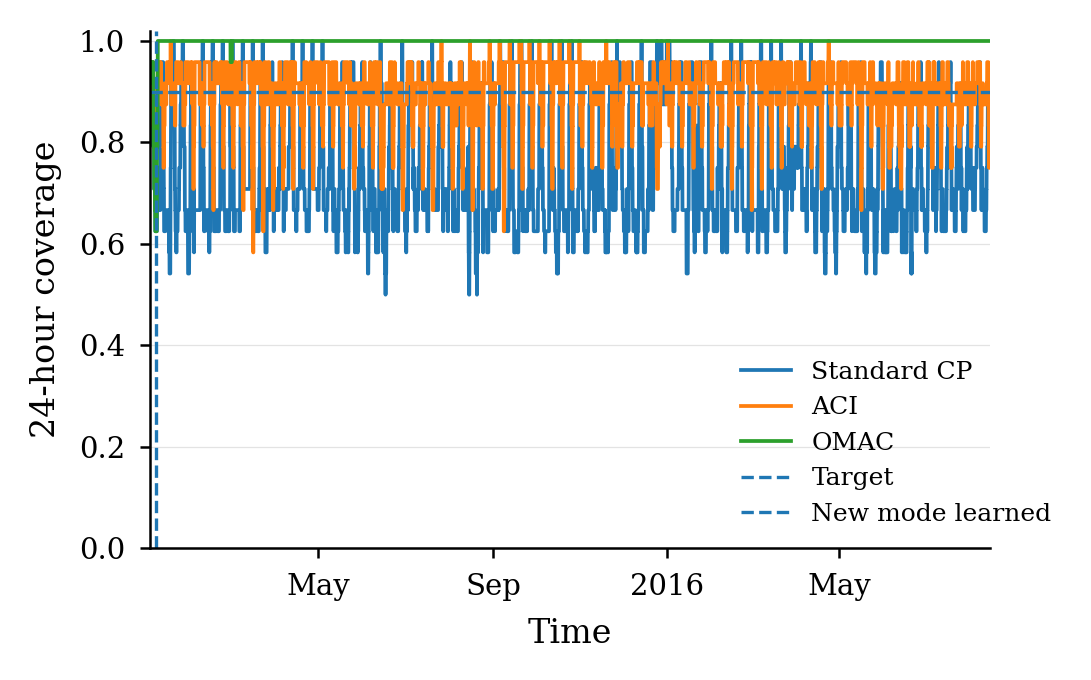


Combined short-warm-up results


,Dataset,Setting,Method,Coverage,Avg. Width,RMSE,Modes Learned,Detections
0,Electricity,"AR(4), 24-h warm-up",Standard CP,0.279875,0.249831,0.283674,NaN,NaN
1,Electricity,"AR(4), 24-h warm-up",ACI,0.789362,0.762161,0.283674,NaN,NaN
2,Electricity,"AR(4), 24-h warm-up",OMAC,0.991269,1.081336,NaN,4.0,3.0
3,Traffic,"AR(4), 24-h warm-up",Standard CP,0.746262,2.503605,1.474558,NaN,NaN
4,Traffic,"AR(4), 24-h warm-up",ACI,0.897884,6.011447,1.474558,NaN,NaN
5,Traffic,"AR(4), 24-h warm-up",OMAC,0.998166,16.488956,NaN,2.0,1.0


In [9]:
# ============================================================
# Short-warm-up experiment
#
# Goal:
#   Test Standard CP, ACI, and the proposed method when the
#   initial mode has seen only a very short portion of the
#   temporal pattern.
#
# Setting:
#   AR(4)
#   12 hours training
#   12 hours calibration
#   12-hour detection window
#   24-hour new-mode construction buffer
#   24-hour rolling coverage
#
# This block does NOT modify the original AR(24) experiment.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque


# ------------------------------------------------------------
# Short-warm-up hyperparameters
# ------------------------------------------------------------

SHORT_AR_ORDER = 4

SHORT_N_TRAIN = 12       # first 12 hours
SHORT_N_CAL = 12         # next 12 hours
SHORT_W = 12             # half-day detection window
SHORT_N_BUILD = 24       # one day for constructing a new mode

SHORT_ROLLING_WINDOW = 24

SHORT_ALPHA = ALPHA
SHORT_GAMMA = ACI_GAMMA
SHORT_DELTA = DELTA


# ============================================================
# Standard CP with explicitly specified AR order
# ============================================================

def run_standard_cp_short(
    y,
    n_train=SHORT_N_TRAIN,
    n_cal=SHORT_N_CAL,
    lag=SHORT_AR_ORDER,
    alpha=SHORT_ALPHA,
):
    y = np.asarray(y, dtype=float)

    test_start = n_train + n_cal

    # Explicit lag=lag is important:
    # the original fit_ar_ridge() default was AR(24).
    ar_model = fit_ar_ridge(
        y[:n_train],
        lag=lag,
    )

    cal_scores = get_calibration_scores(
        ar_model,
        y,
        n_train,
        test_start,
    )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []

    for t in range(test_start, len(y)):

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q
        hi = pred + q

        predictions.append(pred)
        lower.append(lo)
        upper.append(hi)

        covered.append(
            lo <= y[t] <= hi
        )

        widths.append(
            hi - lo
        )

    return {
        "prediction": np.asarray(predictions),
        "lower": np.asarray(lower),
        "upper": np.asarray(upper),
        "covered": np.asarray(
            covered,
            dtype=bool,
        ),
        "width": np.asarray(widths),
        "q": q,
        "model": ar_model,
        "calibration_scores": cal_scores,
        "test_start": test_start,
    }


# ============================================================
# ACI with explicitly specified AR order
# ============================================================

def run_aci_short(
    y,
    n_train=SHORT_N_TRAIN,
    n_cal=SHORT_N_CAL,
    lag=SHORT_AR_ORDER,
    alpha=SHORT_ALPHA,
    gamma=SHORT_GAMMA,
):
    y = np.asarray(y, dtype=float)

    test_start = n_train + n_cal

    ar_model = fit_ar_ridge(
        y[:n_train],
        lag=lag,
    )

    initial_scores = get_calibration_scores(
        ar_model,
        y,
        n_train,
        test_start,
    )

    score_buffer = deque(
        initial_scores.tolist(),
        maxlen=n_cal,
    )

    alpha_t = alpha

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []

    alpha_history = []
    q_history = []

    for t in range(test_start, len(y)):

        scores_now = np.asarray(
            score_buffer,
            dtype=float,
        )

        # Finite calibration resolution
        min_alpha = 1.0 / (
            len(scores_now) + 1
        )

        alpha_for_quantile = np.clip(
            alpha_t,
            min_alpha,
            1.0,
        )

        q_t = conformal_quantile(
            scores_now,
            alpha_for_quantile,
        )

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q_t
        hi = pred + q_t

        miss = int(
            not (lo <= y[t] <= hi)
        )

        predictions.append(pred)
        lower.append(lo)
        upper.append(hi)

        covered.append(
            miss == 0
        )

        widths.append(
            hi - lo
        )

        alpha_history.append(
            alpha_t
        )

        q_history.append(
            q_t
        )

        # ACI update
        alpha_t = (
            alpha_t
            +
            gamma * (
                alpha - miss
            )
        )

        # Add residual after constructing interval
        new_score = abs(
            y[t] - pred
        )

        score_buffer.append(
            new_score
        )

    return {
        "prediction": np.asarray(predictions),
        "lower": np.asarray(lower),
        "upper": np.asarray(upper),
        "covered": np.asarray(
            covered,
            dtype=bool,
        ),
        "width": np.asarray(widths),
        "alpha_history": np.asarray(
            alpha_history
        ),
        "q_history": np.asarray(
            q_history
        ),
        "model": ar_model,
        "test_start": test_start,
    }


# ============================================================
# Short-buffer mode constructor
# ============================================================

def build_mode_from_buffer_short(
    buffer,
    mode_id,
    created_at,
    lag=SHORT_AR_ORDER,
    alpha=SHORT_ALPHA,
):
    """
    Construct a new mode from a short buffer.

    With SHORT_N_BUILD = 24:
        first 12 hours -> fit AR(4)
        next 12 hours  -> conformal calibration
    """

    buffer = np.asarray(
        buffer,
        dtype=float,
    )

    split = len(buffer) // 2

    if split <= lag:
        raise ValueError(
            f"Mode-building training portion "
            f"({split}) must be larger than "
            f"AR order ({lag})."
        )

    train_segment = buffer[:split]

    ar_model = fit_ar_ridge(
        train_segment,
        lag=lag,
    )

    cal_scores = []

    for t in range(
        split,
        len(buffer),
    ):

        pred = predict_ar(
            ar_model,
            buffer,
            t,
        )

        cal_scores.append(
            abs(
                buffer[t] - pred
            )
        )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    return ModeModel(
        mode_id=mode_id,
        ar_model=ar_model,
        q=q,
        created_at=created_at,
    )


# ============================================================
# OMAC mode-adaptive CP for short warm-up
# ============================================================

def run_mode_learning_cp_short(
    y,
    n_train=SHORT_N_TRAIN,
    n_cal=SHORT_N_CAL,
    lag=SHORT_AR_ORDER,
    alpha=SHORT_ALPHA,
    W=SHORT_W,
    n_build=SHORT_N_BUILD,
    delta=SHORT_DELTA,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    test_start = (
        n_train + n_cal
    )

    threshold = compute_detection_threshold(
        W,
        alpha,
        delta,
    )

    # --------------------------------------------------------
    # Initial mode
    #
    # First 12 hours:
    #     AR(4) training
    #
    # Next 12 hours:
    #     conformal calibration
    # --------------------------------------------------------

    initial_ar = fit_ar_ridge(
        y[:n_train],
        lag=lag,
    )

    initial_scores = get_calibration_scores(
        initial_ar,
        y,
        n_train,
        test_start,
    )

    initial_q = conformal_quantile(
        initial_scores,
        alpha,
    )

    modes = [
        ModeModel(
            mode_id=1,
            ar_model=initial_ar,
            q=initial_q,
            created_at=test_start - 1,
        )
    ]

    # Recent union miscoverage
    error_window = deque(
        maxlen=W
    )

    collecting = False
    candidate_buffer = []

    detection_times = []
    mode_creation_times = []

    covered = []
    widths = []

    hull_lower = []
    hull_upper = []

    number_of_modes = []
    covering_modes_history = []

    # --------------------------------------------------------
    # Online process
    # --------------------------------------------------------

    for t in range(
        test_start,
        len(y),
    ):

        intervals = []
        covering_modes = []

        # ----------------------------------------------------
        # Construct one interval from every learned mode
        # ----------------------------------------------------

        for mode in modes:

            pred = predict_ar(
                mode.ar_model,
                y,
                t,
            )

            lo = pred - mode.q
            hi = pred + mode.q

            intervals.append(
                (lo, hi)
            )

            if lo <= y[t] <= hi:

                covering_modes.append(
                    mode.mode_id
                )

        # ----------------------------------------------------
        # Prediction set = union of all mode intervals
        # ----------------------------------------------------

        is_covered = (
            len(covering_modes) > 0
        )

        miss = int(
            not is_covered
        )

        covered.append(
            is_covered
        )

        widths.append(
            interval_union_width(
                intervals
            )
        )

        hull_lower.append(
            min(
                lo
                for lo, hi
                in intervals
            )
        )

        hull_upper.append(
            max(
                hi
                for lo, hi
                in intervals
            )
        )

        number_of_modes.append(
            len(modes)
        )

        covering_modes_history.append(
            covering_modes
        )

        # ----------------------------------------------------
        # Currently collecting observations for a new mode
        # ----------------------------------------------------

        if collecting:

            candidate_buffer.append(
                y[t]
            )

            if (
                len(candidate_buffer)
                >= n_build
            ):

                new_mode = (
                    build_mode_from_buffer_short(
                        candidate_buffer,
                        mode_id=len(modes) + 1,
                        created_at=t,
                        lag=lag,
                        alpha=alpha,
                    )
                )

                modes.append(
                    new_mode
                )

                mode_creation_times.append(
                    t
                )

                collecting = False
                candidate_buffer = []

                # Restart detector after mode creation
                error_window.clear()

        # ----------------------------------------------------
        # Distribution-shift detection
        # ----------------------------------------------------

        else:

            error_window.append(
                miss
            )

            if (
                len(error_window) == W
                and
                sum(error_window)
                >= threshold
            ):

                detection_times.append(
                    t
                )

                collecting = True
                candidate_buffer = []

                error_window.clear()

    return {
        "covered": np.asarray(
            covered,
            dtype=bool,
        ),

        "width": np.asarray(
            widths,
            dtype=float,
        ),

        "hull_lower": np.asarray(
            hull_lower,
            dtype=float,
        ),

        "hull_upper": np.asarray(
            hull_upper,
            dtype=float,
        ),

        "num_modes": np.asarray(
            number_of_modes,
            dtype=int,
        ),

        "covering_modes":
            covering_modes_history,

        "modes": modes,

        "detection_times":
            detection_times,

        "mode_creation_times":
            mode_creation_times,

        "threshold": threshold,

        "test_start": test_start,
    }


# ============================================================
# 24-hour rolling coverage plot
# ============================================================

def plot_short_rolling_coverage(
    time_index,
    standard,
    aci,
    proposed,
    dataset_name,
    save_name,
    rolling_window=SHORT_ROLLING_WINDOW,
):

    rolling_standard = pd.Series(
        standard["covered"].astype(float),
        index=time_index,
    ).rolling(
        rolling_window,
        min_periods=rolling_window,
    ).mean()

    rolling_aci = pd.Series(
        aci["covered"].astype(float),
        index=time_index,
    ).rolling(
        rolling_window,
        min_periods=rolling_window,
    ).mean()

    rolling_proposed = pd.Series(
        proposed["covered"].astype(float),
        index=time_index,
    ).rolling(
        rolling_window,
        min_periods=rolling_window,
    ).mean()

    fig, ax = plt.subplots(
        figsize=(3.5, 2.3)
    )

    ax.plot(
        rolling_standard.index,
        rolling_standard.values,
        label="Standard CP",
        linewidth=0.9,
    )

    ax.plot(
        rolling_aci.index,
        rolling_aci.values,
        label="ACI",
        linewidth=0.9,
    )

    ax.plot(
        rolling_proposed.index,
        rolling_proposed.values,
        label="OMAC",
        linewidth=0.9,
    )

    ax.axhline(
        1.0 - SHORT_ALPHA,
        linestyle="--",
        linewidth=0.8,
        label="Target",
    )

    # Mark learned modes
    test_start = proposed[
        "test_start"
    ]

    for i, creation_t in enumerate(
        proposed["mode_creation_times"]
    ):

        local_idx = (
            creation_t - test_start
        )

        if (
            0 <= local_idx
            < len(time_index)
        ):

            creation_time = (
                time_index[
                    local_idx
                ]
            )

            ax.axvline(
                creation_time,
                linestyle="--",
                linewidth=0.8,
                label=(
                    "New mode learned"
                    if i == 0
                    else None
                ),
            )

    ax.set_xlabel(
        "Time"
    )

    ax.set_ylabel(
        "24-hour coverage"
    )

    ax.set_ylim(
        0.0,
        1.02,
    )

    ax.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    ax.legend(
        fontsize=6,
        frameon=False,
        ncol=1,
        loc="lower right",
        bbox_to_anchor=(1.1, 0.0),
    )

    ax.margins(x=0)

    format_time_axis(
        ax
    )

    fig.subplots_adjust(
        left=0.18,
        right=0.98,
        top=0.96,
        bottom=0.21,
    )

    plt.savefig(
        f"{save_name}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{save_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ============================================================
# Run complete short-warm-up experiment
# ============================================================

def run_short_warmup_experiment(
    series,
    dataset_name,
    save_prefix,
):

    y = np.asarray(
        series.values,
        dtype=float,
    )

    n_train = SHORT_N_TRAIN
    n_cal = SHORT_N_CAL

    test_start = (
        n_train + n_cal
    )

    print()
    print("=" * 70)
    print(
        f"{dataset_name}: "
        f"AR({SHORT_AR_ORDER}) short-warm-up experiment"
    )
    print("=" * 70)

    print(
        "Total observations:",
        len(y),
    )

    print(
        "AR order:",
        SHORT_AR_ORDER,
    )

    print(
        "Training observations:",
        n_train,
        "(12 hours)",
    )

    print(
        "Calibration observations:",
        n_cal,
        "(12 hours)",
    )

    print(
        "Total initial warm-up:",
        test_start,
        "(24 hours)",
    )

    print(
        "Testing observations:",
        len(y) - test_start,
    )

    print(
        "Detection window:",
        SHORT_W,
        "hours",
    )

    print(
        "Mode-building window:",
        SHORT_N_BUILD,
        "hours",
    )

    # --------------------------------------------------------
    # Standard CP
    # --------------------------------------------------------

    standard = run_standard_cp_short(
        y,
    )

    # --------------------------------------------------------
    # ACI
    # --------------------------------------------------------

    aci = run_aci_short(
        y,
    )

    # --------------------------------------------------------
    # OMAC
    # --------------------------------------------------------

    proposed = run_mode_learning_cp_short(
        y,
    )

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    summary = summarize_results(
        dataset_name,
        y,
        standard,
        aci,
        proposed,
    )

    summary.insert(
        1,
        "Setting",
        "AR(4), 24-h warm-up",
    )

    print()
    print(
        summary.to_string(
            index=False
        )
    )

    print()
    print(
        "Detection threshold:",
        proposed["threshold"],
    )

    print(
        "Number of learned modes:",
        len(
            proposed["modes"]
        ),
    )

    print(
        "Number of detected shifts:",
        len(
            proposed[
                "detection_times"
            ]
        ),
    )

    # --------------------------------------------------------
    # Detection timestamps
    # --------------------------------------------------------

    if (
        len(
            proposed[
                "detection_times"
            ]
        ) > 0
    ):

        print(
            "Detection times:"
        )

        for t in proposed[
            "detection_times"
        ]:

            print(
                "  ",
                series.index[t],
            )

    # --------------------------------------------------------
    # New-mode creation timestamps
    # --------------------------------------------------------

    if (
        len(
            proposed[
                "mode_creation_times"
            ]
        ) > 0
    ):

        print(
            "Mode creation times:"
        )

        for t in proposed[
            "mode_creation_times"
        ]:

            print(
                "  ",
                series.index[t],
            )

    # --------------------------------------------------------
    # Rolling coverage
    # --------------------------------------------------------

    test_index = series.index[
        test_start:
    ]

    plot_short_rolling_coverage(
        time_index=test_index,
        standard=standard,
        aci=aci,
        proposed=proposed,
        dataset_name=dataset_name,
        save_name=(
            f"{save_prefix}"
            "_short_warmup_coverage"
        ),
    )

    return {
        "standard": standard,
        "aci": aci,
        "proposed": proposed,
        "summary": summary,
    }


# ============================================================
# Electricity
# ============================================================

electricity_short_results = (
    run_short_warmup_experiment(
        electricity_experiment_series,
        dataset_name="Electricity",
        save_prefix="electricity",
    )
)


# ============================================================
# Traffic
# ============================================================

traffic_short_results = (
    run_short_warmup_experiment(
        traffic_experiment_series,
        dataset_name="Traffic",
        save_prefix="traffic",
    )
)


# ============================================================
# Combined table
# ============================================================

short_warmup_results = pd.concat(
    [
        electricity_short_results[
            "summary"
        ],
        traffic_short_results[
            "summary"
        ],
    ],
    ignore_index=True,
)

print()
print("=" * 70)
print("Combined short-warm-up results")
print("=" * 70)

display(
    short_warmup_results
)

short_warmup_results.to_csv(
    "short_warmup_cp_comparison.csv",
    index=False,
)